# GRACE-RUL: corruption, recovery, prediction, and sensor fault explanations

This notebook implements the finalized architecture in `docs/FINAL_ARCHITECTURE.md`:
**fault detector → selective BiLSTM recovery with WGAN-GP → gated CNN–GRU / Transformer → bounded residual correction → SHAP + LIME**.

It uses the `grace_rul/` package so the website loads exactly the same model definitions.
Keep this notebook, that package, and `data/` together. Install `requirements.txt` or run
`bash scripts/setup_env.sh`, then choose the **Python (GRACE-RUL)** kernel.

The default `QUICK_RUN = False` trains all four subsets with five seeds using CUDA.
PyTorch must detect an accessible GPU; a CUDA request never silently falls back to CPU.
Set it to `True` only for a small FD001 execution check. Quick artifacts are clearly
labeled and are not benchmark evidence. A full run has a substantial compute cost.
Neither this notebook nor its artifact claims superiority before matched experiments.

In [1]:
from pathlib import Path
import os, sys, json, platform

start = Path(os.environ.get('GRACE_PROJECT_ROOT', Path.cwd())).resolve()
PROJECT_ROOT = next((p for p in [start, *start.parents] if (p / 'grace_rul').is_dir() and (p / 'data').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open the notebook alongside grace_rul/ and data/, or set GRACE_PROJECT_ROOT.')
sys.path.insert(0, str(PROJECT_ROOT))
os.environ.setdefault('MPLCONFIGDIR', str(PROJECT_ROOT / 'artifacts' / '.matplotlib'))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, SVG
from grace_rul.config import DEFAULT_CONFIG, quick_config, SENSORS, SENSOR_NAMES
from grace_rul.model import GraceRUL
from grace_rul.data import load_subset, split_engines, OperatingRegimeScaler, WindowDataset
from grace_rul.training import seed_all, device_for
from grace_rul.artifacts import run_experiment, load_bundle
from grace_rul.explain import explain_window

print('Project:', PROJECT_ROOT)
print('Python:', platform.python_version(), '| Torch:', torch.__version__, '| CUDA:', torch.cuda.is_available())

Project: /home/vishal/D drive/minor_latest
Python: 3.14.7 | Torch: 2.11.0+cu128 | CUDA: True


## Configuration and execution budget

The full configuration uses a 70-cycle global window, 30-cycle local branch, 21 sensors,
three settings, a two-layer BiLSTM generator, and two Transformer layers with four heads.
Corruption labels supervise detection/recovery only; they are never inference features.
The critic is training-only. Training targets are capped at 125; evaluation reports capped
and original official targets separately. Empirical intervals are not conformal guarantees.

Full runs train separate models for each subset. Seeds are selected using validation
performance, never test scores. Training explicitly requests `CONFIG['device'] = 'cuda'`.
Use `nvidia-smi` and the GPU check in README.md before starting. An intentional CPU
execution check requires changing the device to `'cpu'`.

In [2]:
QUICK_RUN = False
CONFIG = dict(DEFAULT_CONFIG)
CONFIG['device'] = 'cuda'
if QUICK_RUN:
    CONFIG = quick_config(CONFIG)

seed_all(CONFIG['seed'], CONFIG['cpu_threads'])
TRAINING_DEVICE = device_for(CONFIG)
print('Training device:', TRAINING_DEVICE)
if TRAINING_DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(TRAINING_DEVICE))
display(pd.DataFrame({'setting': list(CONFIG), 'value': [str(v) for v in CONFIG.values()]}))
display(Markdown('**Execution check only: small data and reduced dimensions.**' if QUICK_RUN else '**Full training: four subsets, five seeds, grouped out-of-fold correction.**'))

Training device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


,setting,value
0,device,cuda
1,validation_fraction,0.2
2,calibration_fraction_of_training,0.1
3,subsets,"['FD001', 'FD002', 'FD003', 'FD004']"
4,sequence_length,70
5,local_length,30
6,target_scale,125.0
7,train_rul_cap,125.0
8,generator_hidden,64
9,generator_layers,2


**Full training: four subsets, five seeds, grouped out-of-fold correction.**

## Architecture

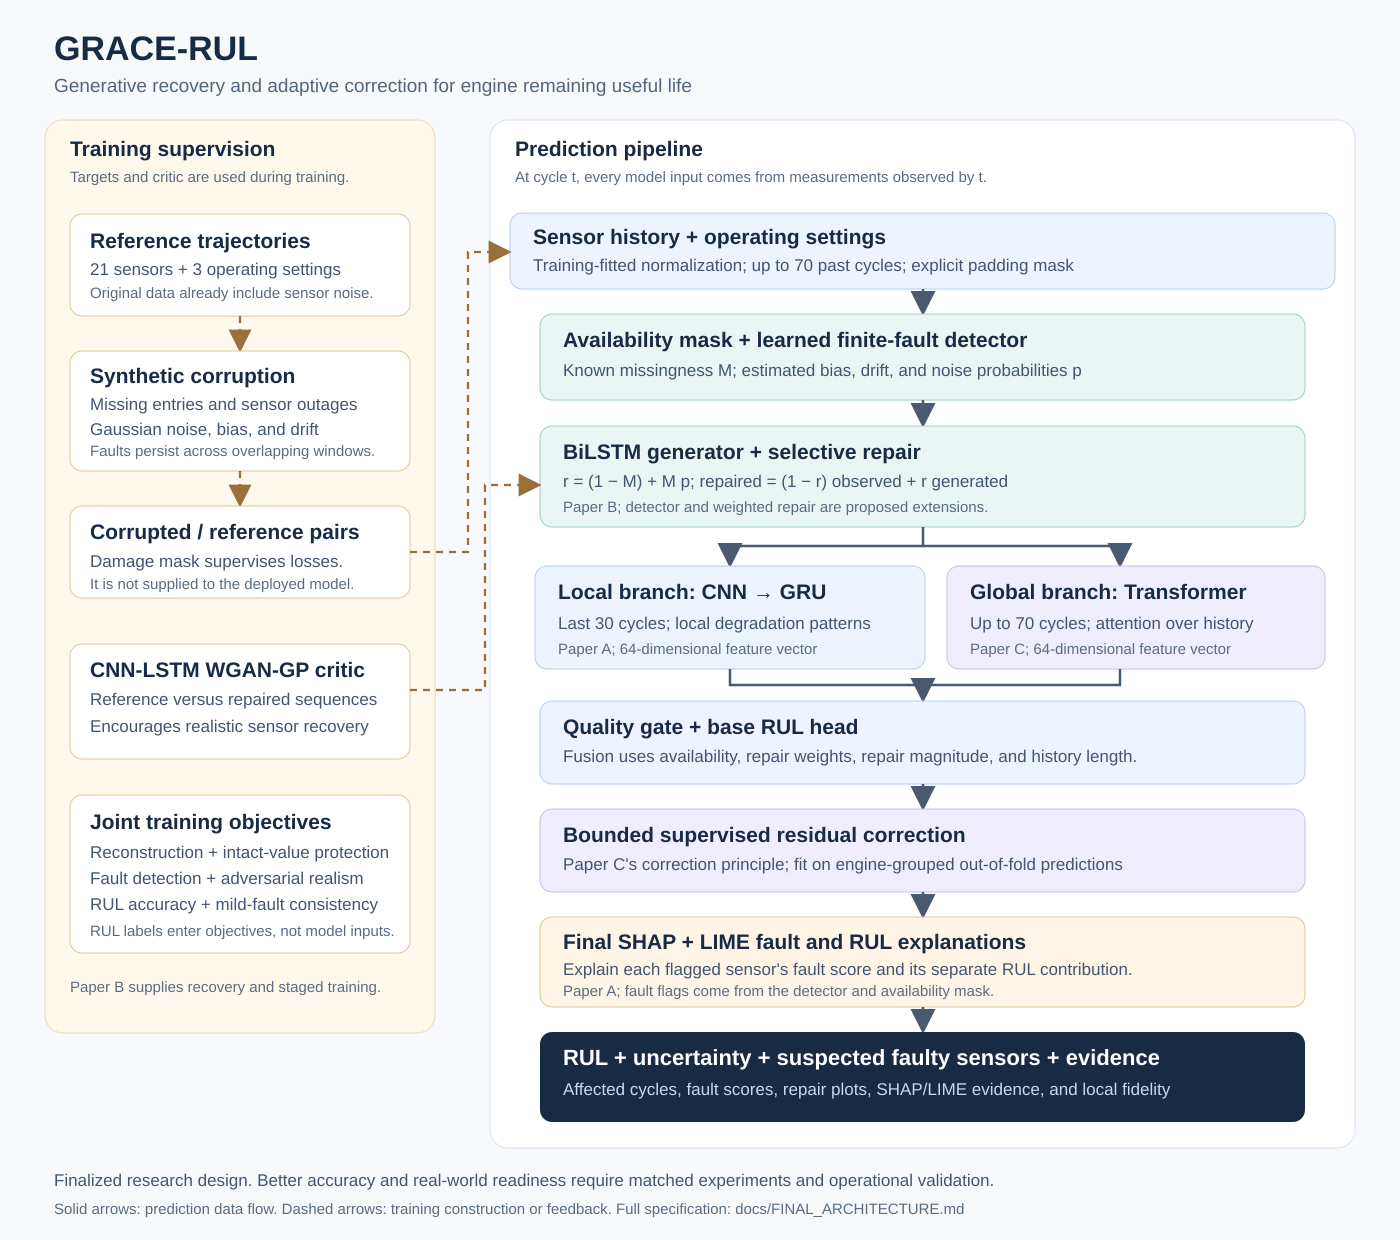

,module,parameters
0,detector,37909
1,generator,176533
2,predictor,132005
3,corrector,4257


GraceRUL(
  (detector): FaultDetector(
    (conv3): Conv1d(45, 32, kernel_size=(3,), stride=(1,), padding=(1,))
    (conv5): Conv1d(45, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (gru): GRU(64, 64, batch_first=True)
    (head): Linear(in_features=64, out_features=21, bias=True)
  )
  (generator): SensorGenerator(
    (encoder): LSTM(66, 64, num_layers=2, batch_first=True, bidirectional=True)
    (decoder): Sequential(
      (0): Linear(in_features=128, out_features=64, bias=True)
      (1): ReLU()
      (2): Linear(in_features=64, out_features=21, bias=True)
    )
  )
  (predictor): RULPredictor(
    (conv3): Conv1d(66, 32, kernel_size=(3,), stride=(1,), padding=(1,))
    (conv5): Conv1d(66, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (gru): GRU(64, 64, batch_first=True)
    (local_projection): Linear(in_features=64, out_features=64, bias=True)
    (input_projection): Linear(in_features=66, out_features=64, bias=True)
    (transformer): TransformerEncoder(
      (lay

In [3]:
display(SVG(filename=str(PROJECT_ROOT / 'docs' / 'GRACE_RUL_architecture.svg')))
model = GraceRUL(CONFIG)
display(pd.DataFrame([{'module': name, 'parameters': sum(p.numel() for p in module.parameters())}
                      for name, module in [('detector', model.detector), ('generator', model.generator),
                                           ('predictor', model.predictor), ('corrector', model.corrector)]]))
print(model)
del model

## Dataset integrity and engine partitions

Read actual file counts instead of trusting conflicting FD004 tables. Split complete
engines into an 80% training pool and 20% validation split. Reserve 10% of the
training pool for independent interval calibration: approximately 72% optimizer
fitting, 8% calibration, and 20% validation overall, with integer-engine rounding.
Regime centers and sensor statistics come only from fitting engines. Windows never
cross an engine boundary. FD002/FD004 fit six operating-regime clusters using the
three settings and normalize sensors separately within each regime. FD001/FD003 use
one regime. Left padding is explicitly masked in all model stages.

In [4]:
inventory = []
for subset in CONFIG['subsets']:
    train, test, truths = load_subset(PROJECT_ROOT / 'data', subset)
    partition = split_engines(train, CONFIG['seed'], CONFIG['maximum_engines'],
                              CONFIG['validation_fraction'], CONFIG['calibration_fraction_of_training'])
    inventory.append({'subset': subset, 'train_engines': train.unit.nunique(), 'test_engines': test.unit.nunique(),
                      'train_rows': len(train), 'test_rows': len(test),
                      'training_pool_engines': len(partition['fit']) + len(partition['calibration']),
                      'operating_conditions': 6 if subset in ['FD002', 'FD004'] else 1,
                      **{name + '_engines': len(units) for name, units in partition.items()}})
    assert len(truths) == test.unit.nunique()
display(pd.DataFrame(inventory))

,subset,train_engines,test_engines,train_rows,test_rows,training_pool_engines,operating_conditions,fit_engines,calibration_engines,validation_engines
0,FD001,100,100,20631,13096,80,1,72,8,20
1,FD002,260,259,53759,33991,208,6,187,21,52
2,FD003,100,100,24720,16596,80,1,72,8,20
3,FD004,249,248,61249,41214,199,6,179,20,50


## Visualize introduced corruption before training

Persistent faults are applied to reference trajectories before making windows, so
overlapping windows share the same fault realization. Reference C-MAPSS measurements
already contain simulation noise. Additional synthetic faults include intermittent loss,
channel outage, missing blocks, Gaussian noise, bias, drift, and mixed families.
Unmodified examples remain in training. The damage mask is a target, not a model input.

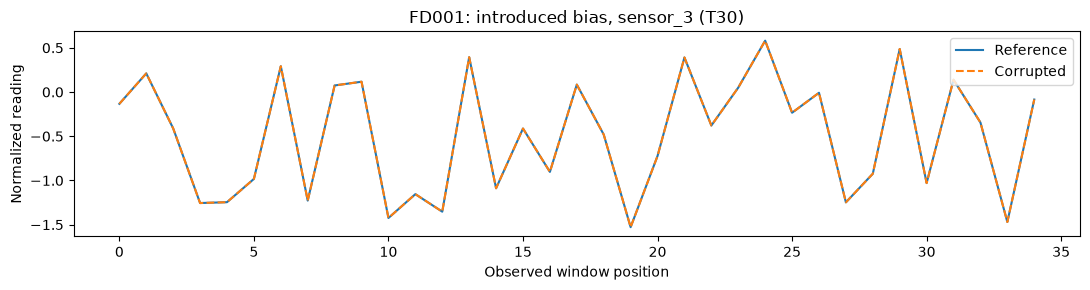

In [5]:
subset = CONFIG['subsets'][0]
train, test, truths = load_subset(PROJECT_ROOT / 'data', subset)
partition = split_engines(train, CONFIG['seed'], CONFIG['maximum_engines'],
                          CONFIG['validation_fraction'], CONFIG['calibration_fraction_of_training'])
fit = train[train.unit.isin(partition['fit'])]
scaler = OperatingRegimeScaler().fit(fit, subset, CONFIG['seed'])
demo = WindowDataset(fit, scaler, CONFIG, mode='correction', family='bias', seed=42)[0]
affected = np.flatnonzero(demo['altered'].any(0).numpy())
j = int(affected[0]) if len(affected) else 2
valid = demo['valid'].numpy()
plt.figure(figsize=(11, 3))
plt.plot(demo['reference'][valid, 3+j], label='Reference')
plt.plot(demo['x'][valid, 3+j], label='Corrupted', linestyle='--')
plt.title(f'{subset}: introduced bias, {SENSORS[j]} ({SENSOR_NAMES[j]})')
plt.xlabel('Observed window position'); plt.ylabel('Normalized reading'); plt.legend(); plt.tight_layout(); plt.show()

## Train and export the complete pipeline

`run_experiment` performs predictor pretraining, detector/generator and WGAN-GP training,
joint recovery/RUL optimization, three-fold engine-disjoint correction fitting, validation
fault-threshold selection, and separate empirical interval calibration. Temporary OOF
models also use independent inner validation engines. The exported audit records these
partitions. No training or calibration stage fits on the official test engines.

Progress includes batch counts, validation, and each temporary OOF model's epochs.
WGAN-GP epochs are slower once the critic starts after warmup. Completed upstream
epochs (including OOF models) are saved in the printed run directory's `checkpoints/`.
To resume after interrupting, restart the kernel and rerun setup/configuration with
the same settings, then pass that run directory as `output_dir` to `run_experiment`.
Completed upstream models load from checkpoints; correction and evaluation rerun.
Older runs containing only CSV results cannot restore their previous weights.

Three-fold metrics evaluate the detector/recovery/predictor on held-out fitting engines
before the final corrector learns from their out-of-fold targets. Fold-level records
and mean/std summaries are saved. They are explicitly upstream CV; the complete
corrected pipeline is evaluated separately on official test files.

It then evaluates clean and corrupted endpoint predictions, unseen severities in full mode,
five seeds, and inference-intervention ablations. Those ablations are labeled accordingly;
retrained paper baselines and retrained module ablations are additional research experiments,
not results manufactured by this notebook.

In [6]:
BUNDLE_PATH, TABLES = run_experiment(PROJECT_ROOT, CONFIG)
RUN_DIR = BUNDLE_PATH.parent
print('Saved:', BUNDLE_PATH)
display(TABLES['seed_summary'])

Run directory: /home/vishal/D drive/minor_latest/artifacts/full_20261008T175019310667Z (completed epochs are checkpointed here)
FD001 seed=42 starting staged training
FD001 seed=42 predictor 1/100: training 24 batches
FD001 seed=42 predictor 1/100: batch 1/24 complete, loss=0.1245, elapsed=0.8s
FD001 seed=42 predictor 1/100: validating clean and corrupted engines
FD001 seed=42 predictor 1: loss=0.0529, validation RMSE=22.874, elapsed=1.3s
FD001 seed=42 predictor 2/100: training 24 batches
FD001 seed=42 predictor 2/100: batch 1/24 complete, loss=0.0268, elapsed=0.0s
FD001 seed=42 predictor 2/100: validating clean and corrupted engines
FD001 seed=42 predictor 2: loss=0.0193, validation RMSE=20.126, elapsed=0.4s
FD001 seed=42 predictor 3/100: training 24 batches
FD001 seed=42 predictor 3/100: batch 1/24 complete, loss=0.0150, elapsed=0.0s
FD001 seed=42 predictor 3/100: validating clean and corrupted engines
FD001 seed=42 predictor 3: loss=0.0133, validation RMSE=18.277, elapsed=0.4s
FD001

KeyboardInterrupt: 

## Training curves and recorded results

The following figures and tables use this run's CSV records. Capped and uncapped
test targets remain separate. Quick results are execution checks. The calibration
interval scope is clean, capped-target endpoints; fault/shift coverage is measured
and must not be assumed.

In [ ]:
history = TABLES['training_history']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for axis, stage in zip(axes, ['predictor', 'generator', 'joint']):
    for (subset, seed), group in history[history.stage == stage].groupby(['subset', 'seed']):
        axis.plot(group.epoch, group.validation_macro_RMSE, marker='o', label=f'{subset}/{seed}')
    axis.set_title(stage.capitalize()); axis.set_xlabel('Epoch'); axis.set_ylabel('Validation RUL RMSE (cycles)')
axes[-1].legend(fontsize=7); fig.tight_layout()
fig.savefig(RUN_DIR / 'training_curves.png', dpi=150); plt.show()
display(TABLES['test_metrics'])
display(TABLES['cross_validation_metrics'])
display(TABLES['cross_validation_summary'])
display(TABLES['robustness_summary'])
display(TABLES['ablation_metrics'])

## Reload the exact website artifact and inspect recovery

The format-3 bundle contains weights, per-subset scalers, correction, sensor thresholds,
empirical interval offsets, fitting-only explanation backgrounds, source hashes, and
engine split audits. It can be loaded with `weights_only=True`. Legacy artifacts are
rejected because their architecture differs.

In [ ]:
bundle, loaded = load_bundle(BUNDLE_PATH, device='cpu')
subset = CONFIG['subsets'][0]
entry = loaded[subset]
train, test, truths = load_subset(PROJECT_ROOT / 'data', subset)
sample_ds = WindowDataset(test[test.unit == test.unit.min()], entry['scaler'], CONFIG,
                          mode='test', family='bias', severity=.2, seed=42, truths=truths)
sample = sample_ds[0]
with torch.no_grad():
    out = entry['model'](sample['x'][None], sample['valid'][None])
valid = sample['valid'].numpy()
fault_scores = out['fault_scores'][0, valid].numpy()
available = np.isfinite(sample['x'][valid, 3:].numpy())
ranked = np.where(available, fault_scores, 0).sum(0) / np.maximum(1, available.sum(0))
suspect = int(ranked.argmax())
sensor_table = pd.DataFrame({'sensor': SENSORS, 'name': SENSOR_NAMES, 'mean_fault_score': ranked,
                             'validation_threshold': entry['entry']['thresholds']})
display(sensor_table.sort_values('mean_fault_score', ascending=False))
plt.figure(figsize=(11, 3))
plt.plot(sample['reference'][valid, 3+suspect], label='Reference')
plt.plot(sample['x'][valid, 3+suspect], label='Observed', linestyle='--')
plt.plot(out['repaired'][0, valid, suspect], label='Recovered')
plt.title(f'Estimated sensor recovery: {SENSORS[suspect]} ({SENSOR_NAMES[suspect]})')
plt.legend(); plt.tight_layout(); plt.savefig(RUN_DIR / 'sensor_recovery.png', dpi=150); plt.show()
print('Final RUL:', float(out['prediction'][0]), 'cycles; correction:', float(out['delta'][0]))

## Final SHAP and LIME sensor-fault explanations

Use actual Kernel SHAP and LIME over coherent sensor/time blocks. Explain the selected
sensor's detector score and final RUL separately. Perturbations preserve missingness,
settings, and padding, and replace sensor blocks with unmodified fitting references.
Backgrounds are selected by operating-setting similarity. LIME reports weighted
held-out perturbation fidelity. SHAP contributions and LIME coefficients have different
scales; agreement is not forced. High RUL importance alone does not establish a fault.

The full run uses three temporal blocks per sensor; quick mode uses one to reduce cost.
Detailed website explanations are computed on demand after an engine is selected.

In [ ]:
explanation = explain_window(entry['model'], sample['x'], sample['valid'],
                             entry['entry']['background'], entry['entry']['background_valid'],
                             target_sensor=suspect, samples=CONFIG['explanation_samples'],
                             seed=CONFIG['seed'], time_blocks=1 if QUICK_RUN else 3)
(RUN_DIR / f'explanation_{subset}.json').write_text(json.dumps(explanation, indent=2))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for axis, target in zip(axes, explanation['targets']):
    values = pd.DataFrame(target['sensors']).head(10).iloc[::-1]
    axis.barh(values.sensor, values.shap)
    axis.set_title(f"SHAP: {target['target']}")
    axis.set_xlabel(target['units'])
    print(target['target'], 'LIME held-out fidelity:', target['lime_holdout_fidelity'])
    display(pd.DataFrame(target['sensors']).head(10))
fig.tight_layout(); fig.savefig(RUN_DIR / 'shap_sensor_evidence.png', dpi=150); plt.show()

## Connect the website

Full bundles in `artifacts/<run>/grace_rul_ALL.pt` are discovered automatically. The
website keeps a model placeholder until one exists. It never invents model metrics.
Quick bundles are excluded from automatic discovery; an explicit selection shows a
quick-validation label.

From the project root, build the frontend with `cd website && npm run build`, then run
`.venv/bin/python -m uvicorn website.backend.app:app --host 127.0.0.1 --port 8000`.
Open `http://127.0.0.1:8000`. Use `GRACE_MODEL_PATH` to select a particular artifact.

In [ ]:
print('Model mode:', 'QUICK validation only' if QUICK_RUN else 'FULL training')
print('Artifact:', BUNDLE_PATH)
print('Explicit model selection:')
print(f'GRACE_MODEL_PATH="{BUNDLE_PATH}" .venv/bin/python -m uvicorn website.backend.app:app --port 8000')
print('Automatic loading remains a placeholder until a full run exists.' if QUICK_RUN else 'Refresh the website model status to load this full run.')